# TF-IDF Baseline Models

In [ ]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from joblib import parallel_config
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import train_test_split
from sklearn.multiclass import OneVsRestClassifier
from sklearn.tree import DecisionTreeClassifier

SEED = 42
TARGETS = ["country", "province", "region_1"]
MIN_TRAIN_REVIEWS = 70
N_JOBS = 6 #change depending on number of cores
BLUE = "#2a78d6"
plt.rcParams.update({
    "figure.figsize": (8, 4),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e4e3df",
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "axes.titleweight": "bold",
})

## Load

In [ ]:
df = pd.read_parquet("data_clean/wine_reviews_clean.parquet")
df.shape

(119922, 16)

## Train / validation / test split

In [ ]:
strata = df["country_group"].fillna("Unknown")
train, rest = train_test_split(df, test_size=0.3, stratify=strata, random_state=SEED)
val, test = train_test_split(rest, test_size=0.5, stratify=strata[rest.index], random_state=SEED)
len(train), len(val), len(test)

(83945, 17988, 17989)

In [ ]:
pd.DataFrame({name: split["country"].value_counts(normalize=True).head(8) * 100 for name, split in
              [("train", train), ("val", val), ("test", test)]}).round(1)

,train,val,test
country,,,
US,42.1,42.1,42.1
France,17.0,17.0,17.0
Italy,14.9,14.9,14.9
Spain,5.1,5.1,5.1
Portugal,4.4,4.4,4.4
Chile,3.5,3.5,3.5
Argentina,3.0,3.0,3.0
Austria,2.5,2.5,2.5


In [ ]:
split_dir = Path("data_clean/splits")
split_dir.mkdir(exist_ok=True)
for name, split in [("train", train), ("val", val), ("test", test)]:
    split.to_parquet(split_dir / f"{name}.parquet", index=False)

## TF-IDF features

In [ ]:
vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=5, max_df=0.9, sublinear_tf=True, max_features=20000)
X_train = vectorizer.fit_transform(train["description"])
X_val = vectorizer.transform(val["description"])
X_test = vectorizer.transform(test["description"])
X_train.shape

(83945, 20000)

## Targets

In [ ]:
keep = {}
summary = []
for target in TARGETS:
    counts = train[target].value_counts()
    keep[target] = counts[counts >= MIN_TRAIN_REVIEWS].index
    summary.append({
        "target": target,
        "all_classes": train[target].nunique(),
        "kept_classes": len(keep[target]),
        "pct_missing": train[target].isna().mean() * 100,
        "pct_rows_kept": train[target].isin(keep[target]).mean() * 100,
    })
pd.DataFrame(summary).set_index("target").round(1)

,all_classes,kept_classes,pct_missing,pct_rows_kept
target,,,,
country,40,18,0.0,99.3
province,395,80,0.0,95.7
region_1,1162,193,16.3,69.0


In [ ]:
def subset(split, X, target):
    mask = split[target].isin(keep[target]).to_numpy()
    return X[mask], split[target].to_numpy()[mask]

## Baseline models

In [ ]:
def make_models():
    return {
        "Most frequent (dummy)": DummyClassifier(strategy="most_frequent"),
        "Logistic regression": OneVsRestClassifier(LogisticRegression(C=10, solver="liblinear"), n_jobs=N_JOBS),
        "Decision tree": DecisionTreeClassifier(max_depth=30, min_samples_leaf=5, random_state=SEED),
    }

In [ ]:
fitted = {}
results = []
for target in TARGETS:
    Xt, yt = subset(train, X_train, target)
    Xv, yv = subset(val, X_val, target)
    for name, model in make_models().items():
        start = time.perf_counter()
        with parallel_config(max_nbytes=None):
            model.fit(Xt, yt)
        pred = model.predict(Xv)
        fitted[target, name] = model
        results.append({
            "target": target,
            "model": name,
            "train_accuracy": accuracy_score(yt, model.predict(Xt)),
            "accuracy": accuracy_score(yv, pred),
            "macro_F1": f1_score(yv, pred, average="macro", zero_division=0),
            "fit_seconds": time.perf_counter() - start,
        })
results = pd.DataFrame(results).set_index(["target", "model"])
results.round(3)

train_accuracy  accuracy  macro_F1  \
target   model                                                       
country  Most frequent (dummy)           0.424     0.424     0.033   
         Logistic regression             0.969     0.857     0.571   
         Decision tree                   0.803     0.648     0.278   
province Most frequent (dummy)           0.292     0.298     0.006   
         Logistic regression             0.971     0.691     0.329   
         Decision tree                   0.597     0.424     0.118   
region_1 Most frequent (dummy)           0.050     0.050     0.000   
         Logistic regression             0.977     0.399     0.266   
         Decision tree                   0.323     0.186     0.085   

                                fit_seconds  
target   model                               
country  Most frequent (dummy)        0.316  
         Logistic regression         20.567  
         Decision tree              130.740  
province Most frequent (dummy)        0.434  
         Logistic regression         40.746  
         Decision tree              163.706  
region_1 Most frequent (dummy)        0.252  
         Logistic regression         59.557  
         Decision tree              134.923

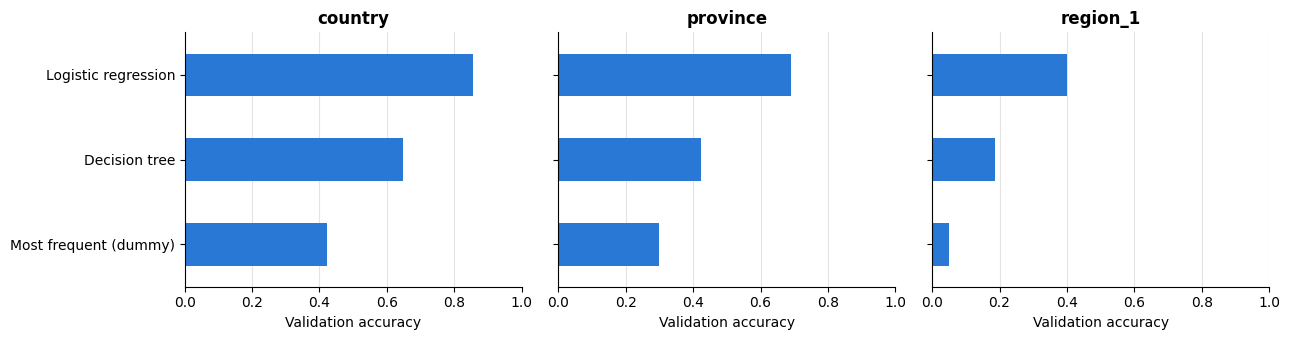

In [ ]:
fig, axes = plt.subplots(1, len(TARGETS), figsize=(13, 3.5), sharex=True)
for ax, target in zip(axes, TARGETS):
    results.loc[target, "accuracy"].sort_values().plot.barh(color=BLUE, ax=ax)
    ax.set(title=target, xlabel="Validation accuracy", ylabel="", xlim=(0, 1))
    ax.grid(axis="y", visible=False)
for ax in axes[1:]:
    ax.tick_params(labelleft=False)
plt.tight_layout()

## Most predictive words by country

In [ ]:
logreg = fitted["country", "Logistic regression"]
words = vectorizer.get_feature_names_out()
coefs = np.vstack([est.coef_[0] for est in logreg.estimators_])
top_words = {country: words[np.argsort(coef)[::-1][:8]] for country, coef in zip(logreg.classes_, coefs)}
pd.DataFrame(top_words).T

,0,1,2,3,4,5,6,7
Argentina,malbec,bonarda,torrontés,malbecs,aromas,argentina,argentine,flavors
Australia,shiraz,australian,australia,barossa,semillon,yellow fruit,cassis,chardonnay
Austria,screwcap,zweigelt,grüner,blaufränkisch,glass stopper,slender,stopper,pepper
Bulgaria,has aromas,flavors of,garnet,cherry,freshly,pleasantly,aromas of,finish
Canada,with notes,gewürz,honey,penetrating,lychee,grape,pure varietal,apricot
Chile,carmenère,chilean,chile,aromas,sb,carignan,olive,casablanca
France,champagne,garrigue,hermitage,château,clairette,provence,chablis,barrel sample
Germany,kabinett,auslese,spätlese,mosel,sweet,riesling,minerality,mineral
Greece,spin,greek,red,white,lead this,start this,lemon,dishes
Hungary,hungarian,honey,has,apricot,honeycomb,tart cherry,hefty,flavors of


## Most common country mistakes

In [ ]:
Xv, yv = subset(val, X_val, "country")
mistakes = pd.DataFrame({"actual": yv, "predicted": logreg.predict(Xv)})
mistakes = mistakes[mistakes["actual"] != mistakes["predicted"]]
mistakes.value_counts().head(10).rename("reviews").to_frame()

reviews
actual    predicted         
Portugal  France         357
Argentina Spain          167
Chile     Spain          159
France    US             122
          Portugal       108
Austria   France          98
Argentina Chile           94
Spain     Chile           93
Australia US              93
Germany   US              92

In [ ]:
per_country = pd.DataFrame({"actual": yv, "correct": logreg.predict(Xv) == yv})
per_country.groupby("actual")["correct"].agg(["size", "mean"]).sort_values("mean").round(3)

,size,mean
actual,,
Canada,34,0.000
Romania,15,0.000
Bulgaria,20,0.150
Hungary,20,0.200
Argentina,531,0.448
New Zealand,191,0.476
Israel,70,0.500
Chile,627,0.512
Portugal,788,0.522


## Test set

In [ ]:
test_results = []
for target in TARGETS:
    best_name = results.loc[target, "macro_F1"].idxmax()
    Xs, ys = subset(test, X_test, target)
    pred = fitted[target, best_name].predict(Xs)
    test_results.append({
        "target": target,
        "model": best_name,
        "accuracy": accuracy_score(ys, pred),
        "macro_F1": f1_score(ys, pred, average="macro", zero_division=0),
    })
pd.DataFrame(test_results).set_index("target").round(3)

,model,accuracy,macro_F1
target,,,
country,Logistic regression,0.856,0.566
province,Logistic regression,0.695,0.345
region_1,Logistic regression,0.398,0.266
